# Classificazione di Testi AI vs Human tramite Multi-Layer Perceptron

***Progetto di Introduzione alla Linguistica Computazionale***

Questo notebook affronta il problema della **AI-generated text detection**, ovvero la classificazione di un testo come scritto da un essere umano o da un modello di linguaggio artificiale.

Il problema viene affrontato confrontando due diverse strategie di rappresentazione dell'input per una rete neurale **Multi-Layer Perceptron (MLP)**:
1. rappresentazione tramite **embedding semantici** del testo;
2. rappresentazione tramite **feature linguistiche** estratte a priori dal dataset.


***Installazione e import di librerie e pacchetti necessari***

In [ ]:
!pip install -q numpy scikit-learn matplotlib torch sentence-transformers

import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
import matplotlib.pyplot as plt
import torch
from sentence_transformers import SentenceTransformer
import pandas as pd


cuda_available = torch.cuda.is_available()
device = torch.device('cuda' if cuda_available else 'cpu')
print(device)


cpu


***Caricamento e overview del dataset***

Il dataset (`ai_vs_human_text_2026.xlsx`) contiene testi etichettati come:
- **0 = Human** → testo scritto da una persona
- **1 = AI** → testo generato da un modello linguistico

Oltre al testo grezzo, per ciascun esempio sono disponibili diverse **feature linguistiche** pre-calcolate, tra cui:
- `readability_grade_level` – livello di leggibilità del testo
- `lexical_diversity_ratio` – varietà lessicale
- `burstiness_index` – variabilità nella lunghezza delle frasi
- `syntactic_variability` – variabilità nella struttura sintattica
- `semantic_coherence_score` – coerenza semantica del testo
- `perplexity_score` – "sorpresa" del modello linguistico nel prevedere il testo



In [ ]:
df = pd.read_excel('/content/ai_vs_human_text_2026.xlsx')

print("Forma:", df.shape)
print("\nTipi delle colonne:\n",df.dtypes)
print("\nBilanciamento etichette (0=Human, 1=AI):\n", df['generated'].value_counts())
print("\nValori nulli:\n", df.isnull().sum())
print("\nValori duplicati:", df.duplicated().sum(), "\n")
print(df.describe())

df.head()

Forma: (1000, 11)

Tipi delle colonne:
 text_id                      object
text                         object
generated                     int64
generation_method            object
prompt_complexity_score     float64
readability_grade_level     float64
lexical_diversity_ratio     float64
burstiness_index            float64
syntactic_variability       float64
semantic_coherence_score    float64
perplexity_score            float64
dtype: object

Bilanciamento etichette (0=Human, 1=AI):
 generated
0    500
1    500
Name: count, dtype: int64

Valori nulli:
 text_id                       0
text                          0
generated                     0
generation_method             0
prompt_complexity_score     500
readability_grade_level       0
lexical_diversity_ratio       0
burstiness_index              0
syntactic_variability         0
semantic_coherence_score      0
perplexity_score              0
dtype: int64

Valori duplicati: 0 

        generated  prompt_complexity_score  reada

,text_id,text,generated,generation_method,prompt_complexity_score,readability_grade_level,lexical_diversity_ratio,burstiness_index,syntactic_variability,semantic_coherence_score,perplexity_score
0,TXT_0001,Many people believe that the landform on Mars ...,0,template+human_variation,NaN,8.326667,0.491597,-0.374609,1.367415,0.893298,810.249639
1,TXT_0002,"""All of our development since World War II has...",0,template+human_variation,NaN,8.067935,0.411093,-0.259151,2.152195,0.874806,856.773380
2,TXT_0003,why shouldn't you use your phone while driving...,0,template+human_variation,NaN,7.538866,0.348606,-0.175882,2.298685,0.908494,785.928513
3,TXT_0004,Hello! Are you in need of advice? Should you t...,0,template+human_variation,NaN,5.626933,0.293501,-0.167261,1.944123,0.922945,544.226529
4,TXT_0005,\nFailure is a common occurrence and one that ...,1,style_simulation,7.555556,10.868516,0.514451,-0.344931,1.832491,0.935746,723.790006


***Generazione degli indici e suddivisione in Training e Testing Set***

Inizialmente, è stato generato un vettore di indici numerici (da $0$ a $999$) corrispondente all'ampiezza del dataset ($N = 1000$).

Tramite la funzione train_test_split, tale vettore viene suddiviso per estrarre gli indici posizionali necessari alla costruzione dei set di addestramento (training) e di valutazione (testing) del modello garantendo l'omogeneità dei dati di input sia per l'approccio basato su embedding, che per la versione che sfrutta, invece, le features linguistiche e stilometriche presenti nel dataset di partenza.

In seguito, dopo aver isolato la colonna del dataset dedicata alle etichette dei singoli testi, sono stati impiegati i medesimi indici posizionali, mediante l'indicizzatore .iloc, per estrarre le etichette da impiegare per il training e il testing.

In [ ]:
indx = np.arange(len(df))
train_idx, test_idx = train_test_split(indx, test_size=0.2, random_state=42)
print(type(train_idx))

# (0=Human, 1=AI)
labels= df['generated']
print(labels)

train_labels= labels.iloc[train_idx]
test_labels= labels.iloc[test_idx]
print(type(train_labels))


<class 'numpy.ndarray'>
0      0
1      0
2      0
3      0
4      1
      ..
995    1
996    1
997    0
998    1
999    1
Name: generated, Length: 1000, dtype: int64
<class 'pandas.core.series.Series'>


***Generazione della matrice di Embeddings con Sentence Transformers***

Per convertire i testi in vettori numerici, viene inizializzato il modello all-MiniLM-L6-v2 di Sentence Transformers. Passando al modello l'intera colonna dei testi sotto forma di lista di stringhe, si ottiene una matrice di embedding con dimensioni $(1000, 384)$.

In questa matrice, le 1000 righe rappresentano i testi e le 384 colonne corrispondono alle caratteristiche vettoriali estratte.Utilizzando gli indici posizionali ricavati nel passaggio precedente, la matrice viene infine suddivisa per isolare il training set e il testing set da destinare ai modelli.

In [ ]:
model = SentenceTransformer("all-MiniLM-L6-v2", device="cpu")

#Conversione testi (input) in embeddings
embeddings = model.encode(list(df['text']))
print(type(embeddings))
print(embeddings.shape)

#Estrazione set di training e testing
train_set1= embeddings[train_idx]
test_set1= embeddings[test_idx]

print(train_set1.shape, type(train_set1),"\n", test_set1.shape, type(test_set1))
print (train_set1)
"ok"

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

... (4 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

<class 'numpy.ndarray'>
(1000, 384)
(800, 384) <class 'numpy.ndarray'> 
 (200, 384) <class 'numpy.ndarray'>
[[-0.0295094  -0.02310758  0.0715467  ...  0.04603327 -0.03032558
  -0.03996673]
 [ 0.13226898  0.00330116  0.05211741 ...  0.05358586 -0.08718471
   0.00486645]
 [-0.01798958 -0.06407629 -0.00128746 ... -0.02776144 -0.00095832
   0.05717437]
 ...
 [ 0.01854094 -0.04026744  0.08769489 ...  0.04087834  0.03756649
  -0.00246477]
 [ 0.04926156 -0.05820801  0.01341339 ... -0.08908091  0.04891436
   0.05191076]
 [-0.02355934 -0.00804446  0.11119033 ...  0.03452339  0.02111901
  -0.01809977]]


'ok'

***Estrazione e normalizzazione dei valori delle caratteristiche linguistiche e stilometriche dei testi***

In questa sezione del codice vengono preparati i dati che costituiscono la seconda modalità di input destinata al modello MLP.

In primo luogo, si isolano in una lista i nomi delle colonne del dataset che contengono gli score delle caratteristiche linguistiche e stilometriche dei testi. L'accesso a tali colonne avviene tramite indicizzazione con parentesi quadre.

Successivamente, richiamando l'attributo .values vengono estratti dal dataframe esclusivamente i valori numerici associati alle colonne selezionate, i quali vengono memorizzati nella variabile features.

Da questa variabile si ricavano il training e il testing set, applicando i medesimi indici posizionali impiegati in precedenza per la configurazione dei set relativi agli embeddings.

Infine, poiché i valori delle caratteristiche linguistiche presentavano un'elevata variabilità di scala, si è reso necessario l'utilizzo della classe StandardScaler per effettuare una standardizzazione dei dati.

In [ ]:
#print(df.columns)
columns= ['readability_grade_level', 'lexical_diversity_ratio', 'burstiness_index', 'syntactic_variability', 'semantic_coherence_score', 'perplexity_score']
features = df[columns].values #matrice array (1000, 6)
print(type(features), features.shape, features)

train_set2= features[train_idx]
test_set2= features[test_idx]
print(type(train_set2))

scaler = StandardScaler()
train_set2 = scaler.fit_transform(train_set2)
test_set2 = scaler.transform(test_set2)

<class 'numpy.ndarray'> (1000, 6) [[ 8.32666667e+00  4.91596639e-01 -3.74609119e-01  1.36741453e+00
   8.93297732e-01  8.10249639e+02]
 [ 8.06793478e+00  4.11092985e-01 -2.59151337e-01  2.15219526e+00
   8.74805868e-01  8.56773380e+02]
 [ 7.53886588e+00  3.48605578e-01 -1.75882179e-01  2.29868454e+00
   9.08494115e-01  7.85928513e+02]
 ...
 [ 9.23440000e+00  4.64000000e-01 -2.11691623e-01  2.11660105e+00
   9.16140258e-01  9.12196950e+02]
 [ 1.28546325e+01  3.97619048e-01 -2.30656169e-01  2.07675833e+00
   9.20797050e-01  1.05308376e+03]
 [ 1.79832100e+01  7.77108434e-01 -3.16377833e-01  5.40125483e+00
   8.75840306e-01  2.69411955e+03]]
<class 'numpy.ndarray'>



 --- REPORT DI VALUTAZIONE Approccio Embeddings---
              precision    recall  f1-score   support

           0       0.71      0.92      0.80       100
           1       0.89      0.63      0.74       100

    accuracy                           0.78       200
   macro avg       0.80      0.78      0.77       200
weighted avg       0.80      0.78      0.77       200


 --- REPORT DI VALUTAZIONE Approccio Dataset Features---
              precision    recall  f1-score   support

           0       0.73      0.79      0.76       100
           1       0.77      0.71      0.74       100

    accuracy                           0.75       200
   macro avg       0.75      0.75      0.75       200
weighted avg       0.75      0.75      0.75       200

<class 'numpy.ndarray'>


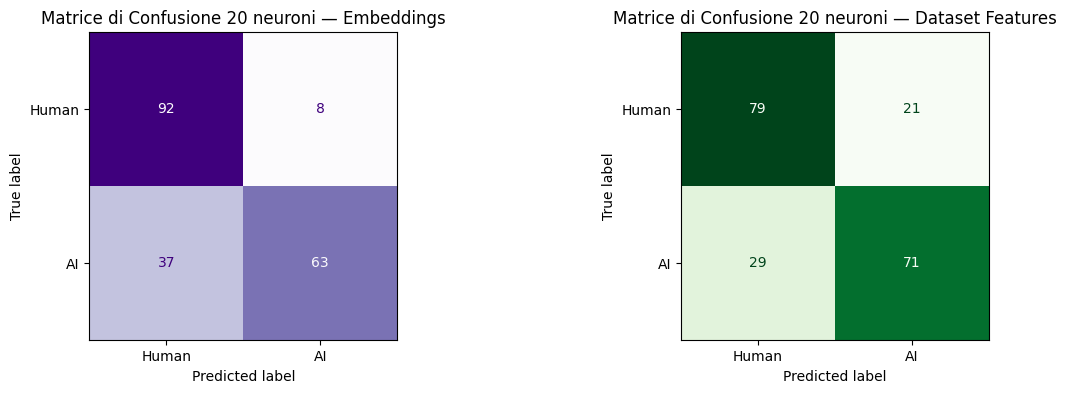




 --- REPORT DI VALUTAZIONE Approccio Embeddings---
              precision    recall  f1-score   support

           0       0.85      0.95      0.90       100
           1       0.94      0.83      0.88       100

    accuracy                           0.89       200
   macro avg       0.90      0.89      0.89       200
weighted avg       0.90      0.89      0.89       200


 --- REPORT DI VALUTAZIONE Approccio Dataset Features---
              precision    recall  f1-score   support

           0       0.75      0.76      0.75       100
           1       0.76      0.74      0.75       100

    accuracy                           0.75       200
   macro avg       0.75      0.75      0.75       200
weighted avg       0.75      0.75      0.75       200

<class 'numpy.ndarray'>


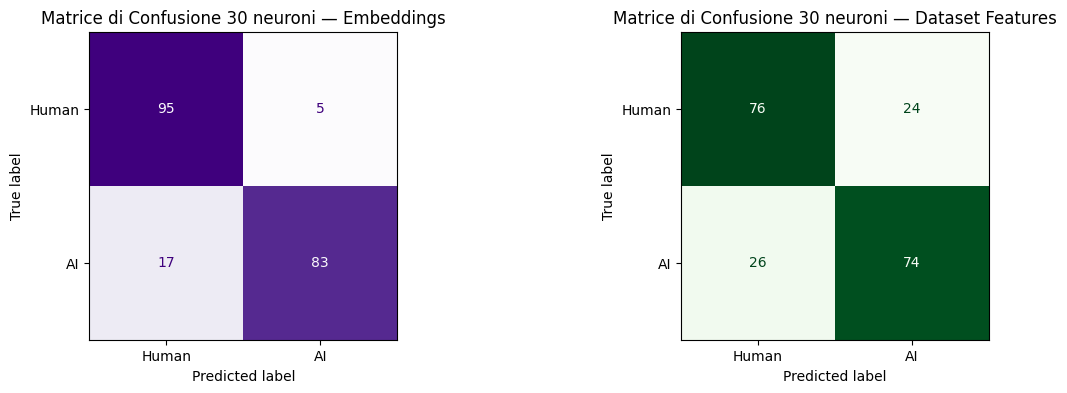




 --- REPORT DI VALUTAZIONE Approccio Embeddings---
              precision    recall  f1-score   support

           0       0.86      0.95      0.90       100
           1       0.94      0.85      0.89       100

    accuracy                           0.90       200
   macro avg       0.90      0.90      0.90       200
weighted avg       0.90      0.90      0.90       200


 --- REPORT DI VALUTAZIONE Approccio Dataset Features---
              precision    recall  f1-score   support

           0       0.73      0.83      0.78       100
           1       0.80      0.69      0.74       100

    accuracy                           0.76       200
   macro avg       0.77      0.76      0.76       200
weighted avg       0.77      0.76      0.76       200

<class 'numpy.ndarray'>


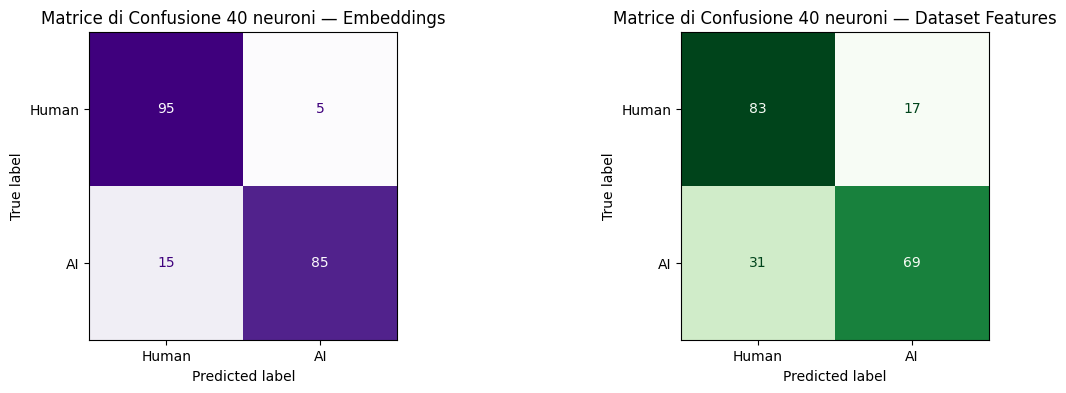




 --- REPORT DI VALUTAZIONE Approccio Embeddings---
              precision    recall  f1-score   support

           0       0.78      0.89      0.83       100
           1       0.87      0.75      0.81       100

    accuracy                           0.82       200
   macro avg       0.83      0.82      0.82       200
weighted avg       0.83      0.82      0.82       200


 --- REPORT DI VALUTAZIONE Approccio Dataset Features---
              precision    recall  f1-score   support

           0       0.70      0.87      0.77       100
           1       0.83      0.62      0.71       100

    accuracy                           0.74       200
   macro avg       0.76      0.74      0.74       200
weighted avg       0.76      0.74      0.74       200

<class 'numpy.ndarray'>


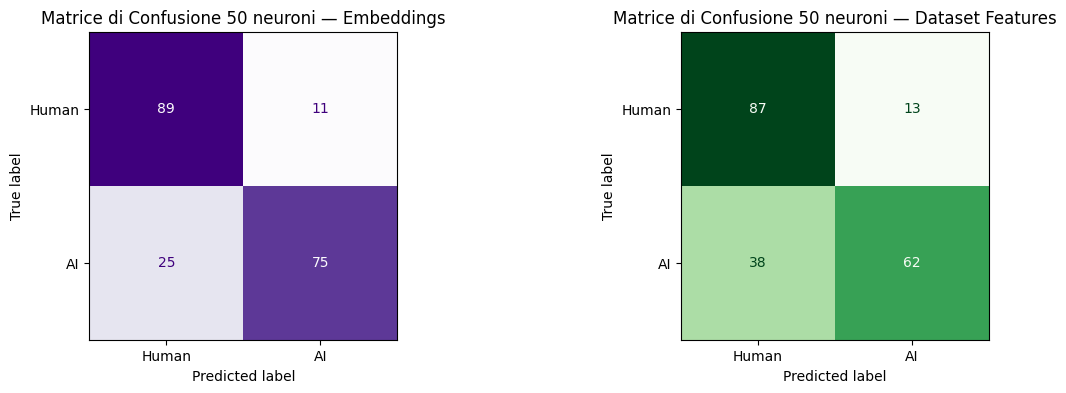




 --- REPORT DI VALUTAZIONE Approccio Embeddings---
              precision    recall  f1-score   support

           0       0.88      0.95      0.91       100
           1       0.95      0.87      0.91       100

    accuracy                           0.91       200
   macro avg       0.91      0.91      0.91       200
weighted avg       0.91      0.91      0.91       200


 --- REPORT DI VALUTAZIONE Approccio Dataset Features---
              precision    recall  f1-score   support

           0       0.75      0.85      0.79       100
           1       0.83      0.71      0.76       100

    accuracy                           0.78       200
   macro avg       0.79      0.78      0.78       200
weighted avg       0.79      0.78      0.78       200

<class 'numpy.ndarray'>


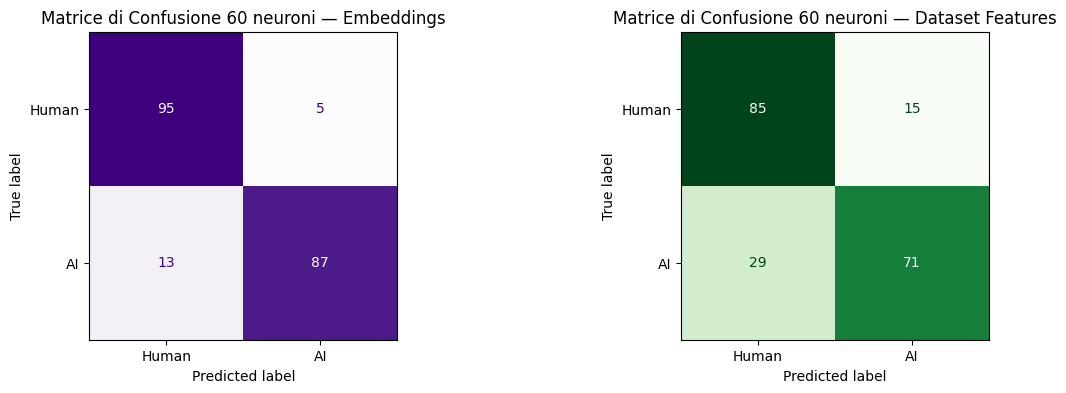




 --- REPORT DI VALUTAZIONE Approccio Embeddings---
              precision    recall  f1-score   support

           0       0.90      0.94      0.92       100
           1       0.94      0.89      0.91       100

    accuracy                           0.92       200
   macro avg       0.92      0.92      0.91       200
weighted avg       0.92      0.92      0.91       200


 --- REPORT DI VALUTAZIONE Approccio Dataset Features---
              precision    recall  f1-score   support

           0       0.79      0.88      0.83       100
           1       0.87      0.77      0.81       100

    accuracy                           0.82       200
   macro avg       0.83      0.82      0.82       200
weighted avg       0.83      0.82      0.82       200

<class 'numpy.ndarray'>


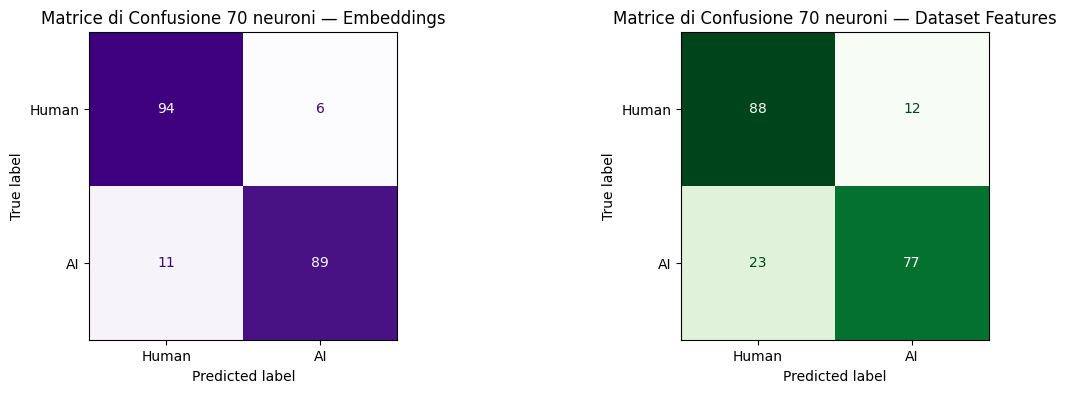




 --- REPORT DI VALUTAZIONE Approccio Embeddings---
              precision    recall  f1-score   support

           0       0.89      0.95      0.92       100
           1       0.95      0.88      0.91       100

    accuracy                           0.92       200
   macro avg       0.92      0.92      0.91       200
weighted avg       0.92      0.92      0.91       200


 --- REPORT DI VALUTAZIONE Approccio Dataset Features---
              precision    recall  f1-score   support

           0       0.77      0.86      0.81       100
           1       0.84      0.74      0.79       100

    accuracy                           0.80       200
   macro avg       0.80      0.80      0.80       200
weighted avg       0.80      0.80      0.80       200

<class 'numpy.ndarray'>


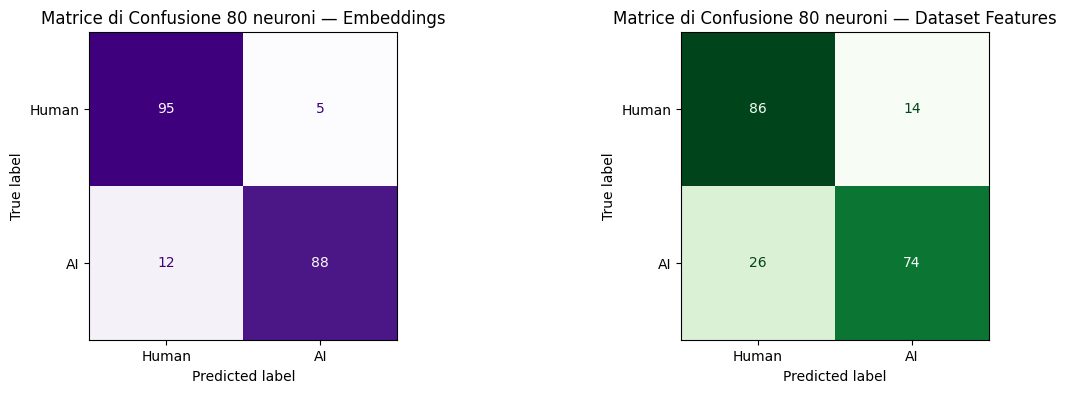




 --- REPORT DI VALUTAZIONE Approccio Embeddings---
              precision    recall  f1-score   support

           0       0.90      0.95      0.92       100
           1       0.95      0.89      0.92       100

    accuracy                           0.92       200
   macro avg       0.92      0.92      0.92       200
weighted avg       0.92      0.92      0.92       200


 --- REPORT DI VALUTAZIONE Approccio Dataset Features---
              precision    recall  f1-score   support

           0       0.76      0.84      0.80       100
           1       0.82      0.74      0.78       100

    accuracy                           0.79       200
   macro avg       0.79      0.79      0.79       200
weighted avg       0.79      0.79      0.79       200

<class 'numpy.ndarray'>


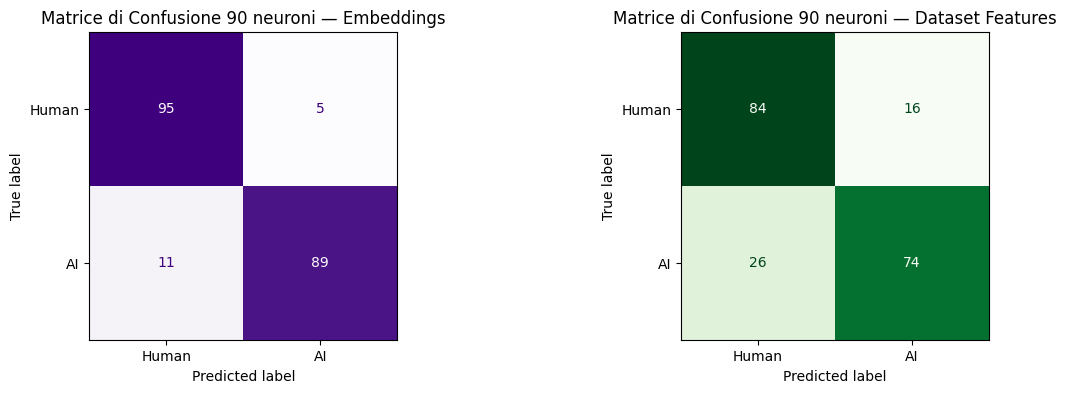




 --- REPORT DI VALUTAZIONE Approccio Embeddings---
              precision    recall  f1-score   support

           0       0.90      0.95      0.92       100
           1       0.95      0.89      0.92       100

    accuracy                           0.92       200
   macro avg       0.92      0.92      0.92       200
weighted avg       0.92      0.92      0.92       200


 --- REPORT DI VALUTAZIONE Approccio Dataset Features---
              precision    recall  f1-score   support

           0       0.78      0.70      0.74       100
           1       0.73      0.80      0.76       100

    accuracy                           0.75       200
   macro avg       0.75      0.75      0.75       200
weighted avg       0.75      0.75      0.75       200

<class 'numpy.ndarray'>


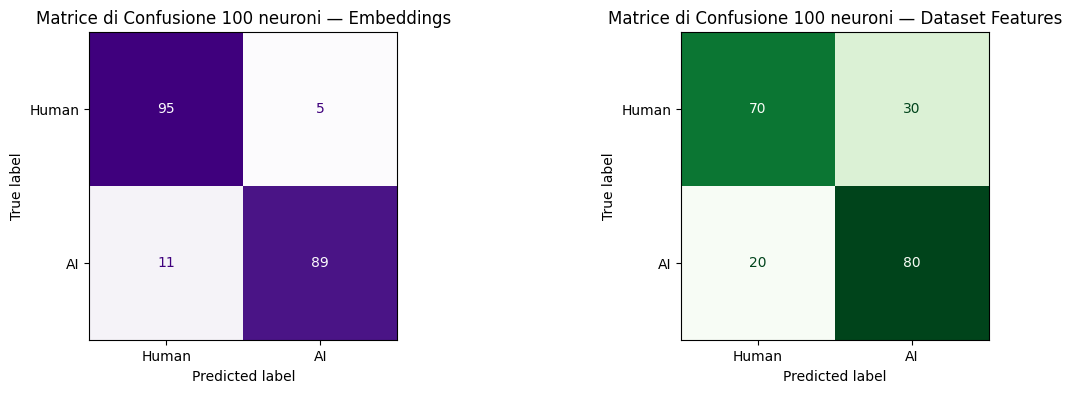




 --- REPORT DI VALUTAZIONE Approccio Embeddings---
              precision    recall  f1-score   support

           0       0.88      0.95      0.91       100
           1       0.95      0.87      0.91       100

    accuracy                           0.91       200
   macro avg       0.91      0.91      0.91       200
weighted avg       0.91      0.91      0.91       200


 --- REPORT DI VALUTAZIONE Approccio Dataset Features---
              precision    recall  f1-score   support

           0       0.82      0.85      0.83       100
           1       0.84      0.81      0.83       100

    accuracy                           0.83       200
   macro avg       0.83      0.83      0.83       200
weighted avg       0.83      0.83      0.83       200

<class 'numpy.ndarray'>


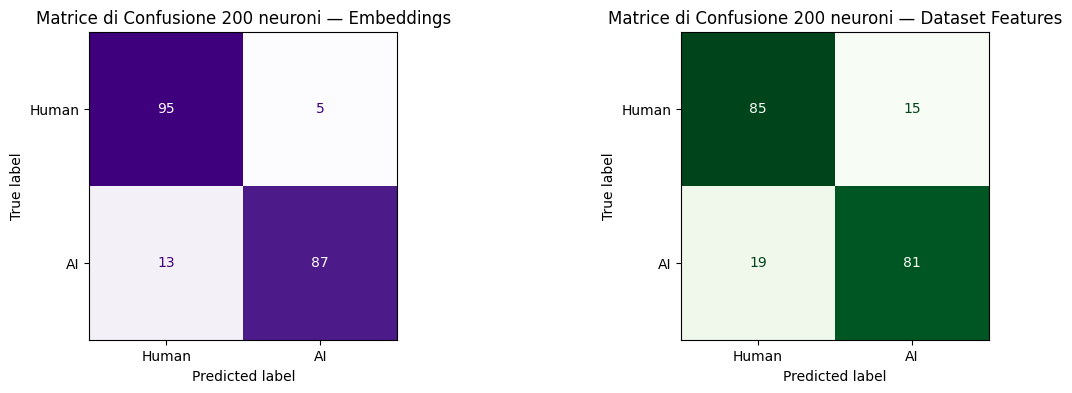




 --- REPORT DI VALUTAZIONE Approccio Embeddings---
              precision    recall  f1-score   support

           0       0.86      0.96      0.91       100
           1       0.96      0.85      0.90       100

    accuracy                           0.91       200
   macro avg       0.91      0.91      0.90       200
weighted avg       0.91      0.91      0.90       200


 --- REPORT DI VALUTAZIONE Approccio Dataset Features---
              precision    recall  f1-score   support

           0       0.71      0.88      0.79       100
           1       0.84      0.64      0.73       100

    accuracy                           0.76       200
   macro avg       0.78      0.76      0.76       200
weighted avg       0.78      0.76      0.76       200

<class 'numpy.ndarray'>


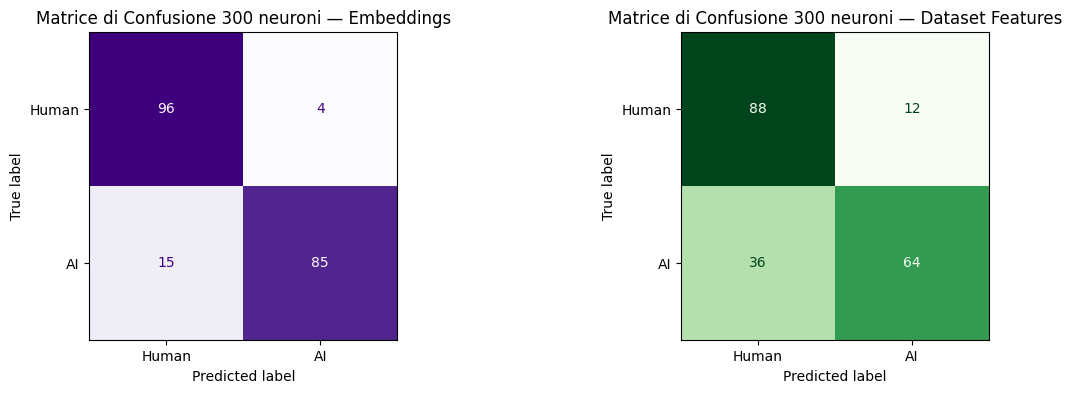




 --- REPORT DI VALUTAZIONE Approccio Embeddings---
              precision    recall  f1-score   support

           0       0.88      0.94      0.91       100
           1       0.94      0.87      0.90       100

    accuracy                           0.91       200
   macro avg       0.91      0.91      0.90       200
weighted avg       0.91      0.91      0.90       200


 --- REPORT DI VALUTAZIONE Approccio Dataset Features---
              precision    recall  f1-score   support

           0       0.83      0.86      0.85       100
           1       0.86      0.83      0.84       100

    accuracy                           0.84       200
   macro avg       0.85      0.84      0.84       200
weighted avg       0.85      0.84      0.84       200

<class 'numpy.ndarray'>


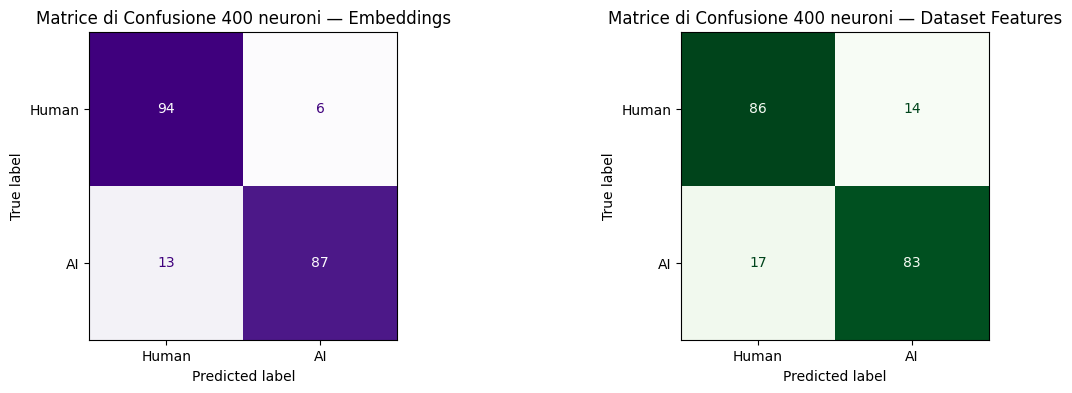




 --- REPORT DI VALUTAZIONE Approccio Embeddings---
              precision    recall  f1-score   support

           0       0.90      0.95      0.93       100
           1       0.95      0.90      0.92       100

    accuracy                           0.93       200
   macro avg       0.93      0.93      0.92       200
weighted avg       0.93      0.93      0.92       200


 --- REPORT DI VALUTAZIONE Approccio Dataset Features---
              precision    recall  f1-score   support

           0       0.78      0.88      0.83       100
           1       0.86      0.75      0.80       100

    accuracy                           0.81       200
   macro avg       0.82      0.81      0.81       200
weighted avg       0.82      0.81      0.81       200

<class 'numpy.ndarray'>


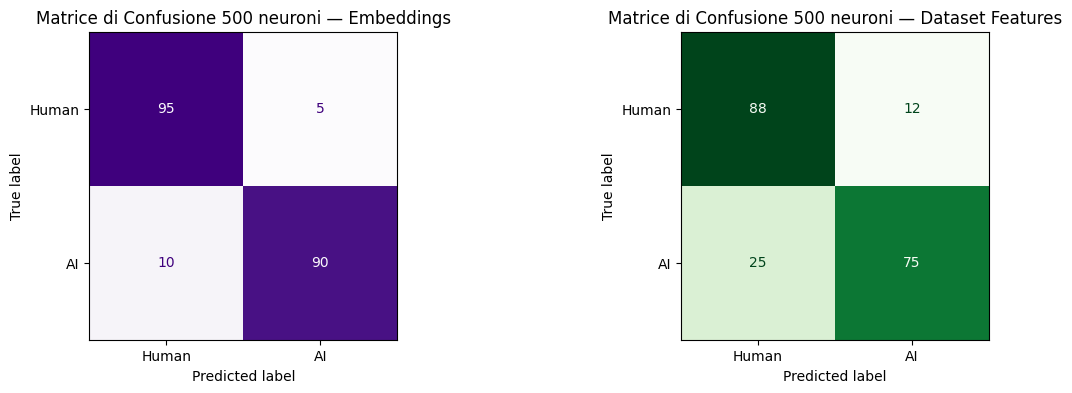

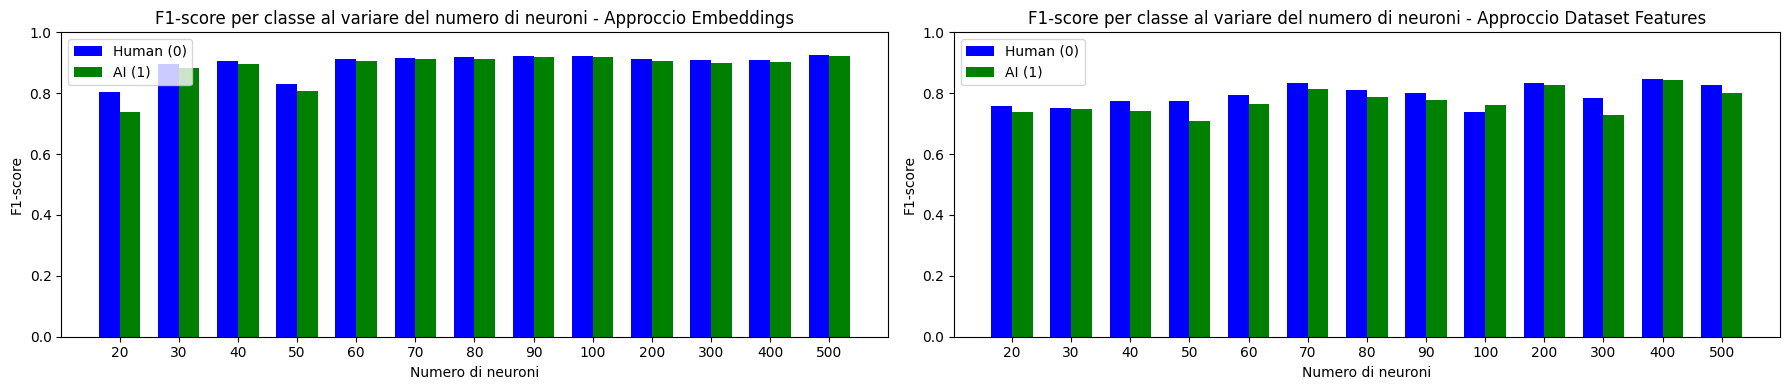

In [ ]:
def variazione_n_neuroni(lista_neuroni, train_set1, test_set1, train_set2, test_set2, train_labels, test_labels):
  f1_human = []
  f1_ai = []

  f1_human2 = []
  f1_ai2 = []

  for n in lista_neuroni:

    # ADDESTRAMENTO E PREDIZIONI DI MLP 2 APPROCCI
    mlp1 = MLPClassifier(hidden_layer_sizes=(n,), random_state=42, early_stopping=True)
    mlp1.fit(train_set1, train_labels)
    predictions1= mlp1.predict(test_set1)

    mlp2 = MLPClassifier(hidden_layer_sizes=(n,), random_state=42, early_stopping=True)
    mlp2.fit(train_set2, train_labels)
    predictions2= mlp2.predict(test_set2)

   # REPORT DI VALUTAZIONE 2 APPROCCI
    print("\n", "--- REPORT DI VALUTAZIONE Approccio Embeddings---")
    report1=classification_report(test_labels, predictions1)
    print(report1)

    print("\n", "--- REPORT DI VALUTAZIONE Approccio Dataset Features---")
    report2=classification_report(test_labels, predictions2)
    print(report2)

    # CONFUSION MATRIX 2 APPROCCI
    # Embeddings
    cm1= confusion_matrix(test_labels, predictions1) #<class 'numpy.ndarray'>
    display1 = ConfusionMatrixDisplay(cm1, display_labels=["Human", "AI"])

    # Dataset Features
    cm2= confusion_matrix(test_labels, predictions2)
    display2 = ConfusionMatrixDisplay(cm2, display_labels=["Human", "AI"])


    # Due subplot affiancati
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))


    #1
    display1.plot(cmap=plt.cm.Purples, ax=ax[0], colorbar=False)
    ax[0].set_title(f"Matrice di Confusione {n} neuroni — Embeddings")

    #2
    display2.plot(cmap=plt.cm.Greens, ax=ax[1], colorbar=False)
    ax[1].set_title(f"Matrice di Confusione {n} neuroni — Dataset Features")

    plt.show()
    print("\n")


    # F1-SCORE DUE APPROCCI
    # 1
    f1_per_classe = f1_score(test_labels, predictions1, average=None, labels=[0, 1])
    f1_human.append(f1_per_classe[0])
    f1_ai.append(f1_per_classe[1])

    # 2
    f1_per_classe2 = f1_score(test_labels, predictions2, average=None, labels=[0, 1])
    f1_human2.append(f1_per_classe2[0])
    f1_ai2.append(f1_per_classe2[1])


  # GRAFICO F1-SCORE DUE APPROCCI
  x = np.arange(len(lista_neuroni))   # posizioni sull'asse x, 13
  larghezza = 0.35                    # larghezza di ogni barra

  fig, ax = plt.subplots(1, 2, figsize=(18, 4))

  ax[0].bar(x - larghezza/2, f1_human, larghezza, label='Human (0)', color='blue')
  ax[0].bar(x + larghezza/2, f1_ai, larghezza, label='AI (1)', color='green')

  ax[1].bar(x - larghezza/2, f1_human2, larghezza, label='Human (0)', color='blue')
  ax[1].bar(x + larghezza/2, f1_ai2, larghezza, label='AI (1)', color='green')

  ax[0].set_xlabel('Numero di neuroni')
  ax[0].set_ylabel('F1-score')
  ax[0].set_title('F1-score per classe al variare del numero di neuroni - Approccio Embeddings')
  ax[0].set_xticks(x) #creiamo 13 ticks, da 0 a 12.
  ax[0].set_xticklabels(lista_neuroni)
  ax[0].set_ylim(0, 1)
  ax[0].legend()

  ax[1].set_xlabel('Numero di neuroni')
  ax[1].set_ylabel('F1-score')
  ax[1].set_title('F1-score per classe al variare del numero di neuroni - Approccio Dataset Features')
  ax[1].set_xticks(x)
  ax[1].set_xticklabels(lista_neuroni)
  ax[1].set_ylim(0, 1)
  ax[1].legend()

  plt.tight_layout()

  plt.show()


lista_neuroni = [20, 30, 40, 50, 60, 70, 80, 90, 100, 200, 300, 400, 500]
variazione_n_neuroni(lista_neuroni, train_set1, test_set1, train_set2, test_set2, train_labels, test_labels)



# Conclusioni
Analizzando come cambiano le prestazioni al variare del numero di neuroni (da 20 a 500), emergono alcune conclusioni chiare sul confronto tra i due approcci.



***Approccio Embeddings***

Il modello basato su all-MiniLM-L6-v2 migliora molto velocemente all'inizio, in particolare, osserviamo come l'accuratezza passa da 0.78 (con 20 neuroni) a 0.89-0.90 già con 30-40 neuroni. Da quel punto in poi, però, i risultati restano stabili tra 0.91 e 0.93, anche arrivando a 500 neuroni.
Questo significa che gli embeddings contengono già abbastanza informazione utile perché bastino poche decine di neuroni per sfruttarla al meglio.


***Approccio Dataset Features***

Il modello basato sulle sette features linguistiche si comporta in modo differnte poichè l'accuratezza non cresce in modo regolare all'aumentare dei neuroni, ma oscilla tra 0.74 e 0.84 senza una direzione chiara.
Ad esempio, il valore più alto si trova a 400 neuroni (0.84), ma valori simili o più bassi compaiono sia con poche unità (20 neuroni: 0.75) sia con quantità intermedie (100 neuroni: 0.75; 300 neuroni: 0.76).
Questo succede probabilmente perché sette sole feature numeriche non contengono abbastanza informazione da giustificare reti molto grandi.

***Confronto tra i due approcci***

In tutte le configurazioni testate, l'approccio basato su embeddings ottiene risultati migliori rispetto a quello basato sulle features linguistiche, con una differenza di accuratezza che va dai 10 ai 17 punti percentuali.
Questo suggerisce che gli embeddings riescono a cogliere meglio le differenze tra testo umano e testo generato da AI, mentre le sette features linguistiche, pur essendo più facili da interpretare (ogni feature ha un significato linguistico chiaro), da sole non bastano a catturare tutta questa differenza.